# Session 1 · Fundamentals of Advanced Data Science

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-01-fundamentals-of-advanced-data-science.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: vectorisation vs loops, and broadcasting

In [1]:
"""Compare a Python loop with NumPy vectorisation and show broadcasting."""
import time
import numpy as np

rng = np.random.default_rng(42)                     # reproducible random numbers
X = rng.normal(loc=[50, 1000, 3], scale=[10, 200, 1], size=(200_000, 3))
print("shape of X:", X.shape)

# --- 1. Pure Python loop (slow) ---------------------------------------
t0 = time.perf_counter()
means = [sum(X[:, j]) / len(X) for j in range(3)]
stds = [(sum((x - means[j]) ** 2 for x in X[:, j]) / len(X)) ** 0.5 for j in range(3)]
Z_loop = [[(X[i, j] - means[j]) / stds[j] for j in range(3)] for i in range(len(X))]
t_loop = time.perf_counter() - t0

# --- 2. NumPy broadcasting (fast) -------------------------------------
t0 = time.perf_counter()
Z = (X - X.mean(axis=0)) / X.std(axis=0)            # (200000,3) - (3,) -> broadcast
t_vec = time.perf_counter() - t0

print(f"loop time       : {t_loop:.2f} s")
print(f"vectorised time : {t_vec:.4f} s")
print(f"speed-up        : about {t_loop / t_vec:,.0f}x")
print("same answer?    :", np.allclose(Z, np.array(Z_loop)))
print("means after     :", Z.mean(axis=0).round(6))
print("stds after      :", Z.std(axis=0).round(6))

# Boolean masks: select rows without a loop
mask = (X[:, 0] > 60) & (X[:, 2] < 2)
print("rows with feature0 > 60 and feature2 < 2:", mask.sum())

shape of X: (200000, 3)


loop time       : 0.40 s
vectorised time : 0.0122 s
speed-up        : about 33x
same answer?    : True
means after     : [ 0.  0. -0.]
stds after      : [1. 1. 1.]
rows with feature0 > 60 and feature2 < 2: 5077


### Example 2 · Intermediate: pandas method chaining, groupby, merge and pivot

In [2]:
"""Advanced pandas: method chaining, groupby-agg, merge, pivot_table and pd.cut."""
import numpy as np
import pandas as pd

rng = np.random.default_rng(7)
n = 1200
sales = pd.DataFrame({
    "date": pd.date_range("2026-01-01", periods=n, freq="7h"),
    "shop_id": rng.integers(1, 7, n),
    "product": rng.choice(["Tea", "Biscuits", "Rice", "Cooking oil"], n, p=[.35, .3, .2, .15]),
    "qty": rng.integers(1, 6, n),
})
shops = pd.DataFrame({"shop_id": range(1, 7),
                      "city": ["Karachi", "Karachi", "Lahore", "Lahore", "Islamabad", "Karachi"]})
price = {"Tea": 450, "Biscuits": 120, "Rice": 380, "Cooking oil": 650}

report = (sales
          .merge(shops, on="shop_id", how="left")                 # add the city column
          .assign(revenue=lambda d: d["qty"] * d["product"].map(price),
                  month=lambda d: d["date"].dt.month_name().str[:3])
          .groupby(["city", "product"], as_index=False)
          .agg(orders=("qty", "size"), units=("qty", "sum"), revenue=("revenue", "sum"))
          .sort_values(["city", "revenue"], ascending=[True, False]))
print(report.to_string(index=False))

# Pivot: cities as rows, products as columns
pivot = (sales.merge(shops, on="shop_id")
         .assign(revenue=lambda d: d["qty"] * d["product"].map(price))
         .pivot_table(index="city", columns="product", values="revenue", aggfunc="sum", margins=True))
print("\nRevenue pivot (Rs):\n", pivot.round(0).astype(int))

# Binning a numeric column into categories
sales["basket"] = pd.cut(sales["qty"], bins=[0, 2, 4, 5], labels=["small", "medium", "large"])
print("\nBasket sizes:\n", sales["basket"].value_counts().sort_index())
print("\nMemory before/after category dtype:",
      sales["product"].memory_usage(deep=True), "->", sales["product"].astype("category").memory_usage(deep=True), "bytes")

     city     product  orders  units  revenue
Islamabad         Tea      77    229   103050
Islamabad Cooking oil      41    128    83200
Islamabad        Rice      37    101    38380
Islamabad    Biscuits      58    152    18240
  Karachi         Tea     220    657   295650
  Karachi Cooking oil      99    311   202150
  Karachi        Rice     116    341   129580
  Karachi    Biscuits     161    482    57840
   Lahore         Tea     152    440   198000
   Lahore        Rice      75    248    94240
   Lahore Cooking oil      42    141    91650
   Lahore    Biscuits     122    384    46080

Revenue pivot (Rs):
 product    Biscuits  Cooking oil    Rice     Tea      All
city                                                     
Islamabad     18240        83200   38380  103050   242870
Karachi       57840       202150  129580  295650   685220
Lahore        46080        91650   94240  198000   429970
All          122160       377000  262200  596700  1358060

Basket sizes:
 basket
small    

### Example 3 · Intermediate: a multi-panel Matplotlib + Seaborn figure

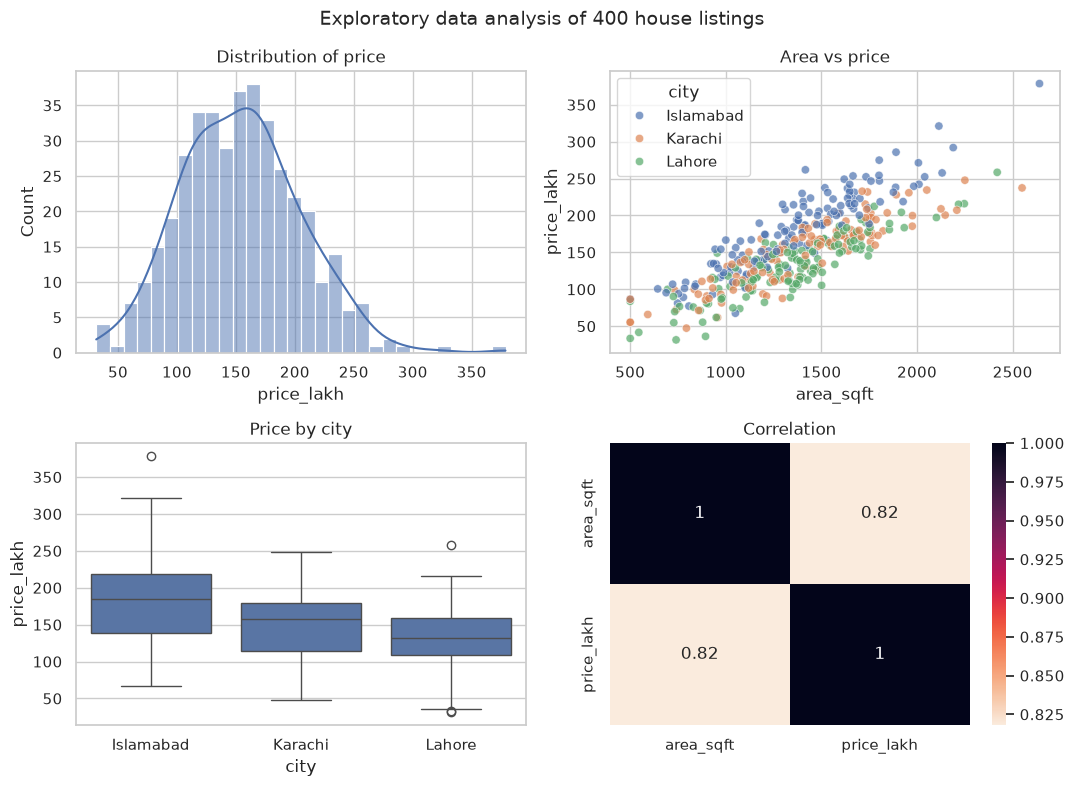

           count   mean    50%    max
city                                 
Islamabad  136.0  181.1  185.4  378.7
Karachi    127.0  150.1  158.2  247.8
Lahore     137.0  131.9  131.7  258.5


In [3]:
"""Build a 2x2 exploratory figure with Matplotlib and Seaborn and save it as a PNG."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(1)
n = 400
df = pd.DataFrame({
    "area_sqft": rng.normal(1400, 400, n).clip(500, 3000).round(),
    "city": rng.choice(["Karachi", "Lahore", "Islamabad"], n),
})
city_premium = df["city"].map({"Karachi": 1.0, "Lahore": 0.9, "Islamabad": 1.2})
df["price_lakh"] = (0.11 * df["area_sqft"] * city_premium + rng.normal(0, 20, n)).round(1)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
sns.histplot(df, x="price_lakh", bins=30, kde=True, ax=axes[0, 0]).set_title("Distribution of price")
sns.scatterplot(df, x="area_sqft", y="price_lakh", hue="city", alpha=.7, ax=axes[0, 1]).set_title("Area vs price")
sns.boxplot(df, x="city", y="price_lakh", ax=axes[1, 0]).set_title("Price by city")
sns.heatmap(df[["area_sqft", "price_lakh"]].corr(), annot=True, cmap="rocket_r", ax=axes[1, 1]).set_title("Correlation")
fig.suptitle("Exploratory data analysis of 400 house listings", fontsize=14)
fig.tight_layout()
fig.savefig("session-01_eda_dashboard.png", dpi=110)
plt.show()

print(df.groupby("city")["price_lakh"].describe()[["count", "mean", "50%", "max"]].round(1))

### Example 4 · Advanced: the scikit-learn API and a Pipeline

In [4]:
"""The scikit-learn estimator API: transformers, models, pipelines, cross-validation."""
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

X, y = load_wine(return_X_y=True)            # 178 wines, 13 chemical features, 3 cultivars
print("X shape:", X.shape, "| classes:", sorted(set(y.tolist())))
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# A transformer learns (fit) then changes data (transform)
scaler = StandardScaler().fit(X_tr)
print("first 3 learned means:", scaler.mean_[:3].round(2))

# Swap models with one line: same fit / score calls
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "KNN without scaling": KNeighborsClassifier(5),
    "Decision tree": DecisionTreeClassifier(random_state=0),
}
print(f"\n{'model':<22}{'test acc':>9}{'5-fold CV':>12}")
for name, model in models.items():
    model.fit(X_tr, y_tr)
    cv = cross_val_score(model, X, y, cv=5)
    print(f"{name:<22}{model.score(X_te, y_te):>9.3f}{cv.mean():>8.3f} ± {cv.std():.3f}")

pipe = models["Logistic regression"]
print("\nprobabilities for first test wine:", pipe.predict_proba(X_te[:1]).round(3))

X shape: (178, 13) | classes: [0, 1, 2]
first 3 learned means: [12.97  2.33  2.37]

model                  test acc   5-fold CV


Logistic regression       1.000   0.983 ± 0.014
KNN (k=5)                 0.933   0.949 ± 0.038
KNN without scaling       0.778   0.691 ± 0.049
Decision tree             0.956   0.888 ± 0.040

probabilities for first test wine: [[0.926 0.072 0.002]]


### Example 5 · Advanced: one data set, three kinds of learning

In [5]:
"""Supervised, unsupervised and reinforcement learning side by side on tiny problems."""
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

X, y = load_iris(return_X_y=True)

# 1) Supervised: labels are given, we learn to predict them
clf = LogisticRegression(max_iter=500).fit(X, y)
print("SUPERVISED   training accuracy:", round(clf.score(X, y), 3))

# 2) Unsupervised: labels hidden, K-means finds 3 groups on its own
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
print("UNSUPERVISED agreement of clusters with true species (ARI):", round(adjusted_rand_score(y, km.labels_), 3))

# 3) Reinforcement: a 3-armed bandit; the agent only sees rewards
rng = np.random.default_rng(0)
true_win_rate = np.array([0.2, 0.5, 0.8])          # unknown to the agent
Q, N, total = np.zeros(3), np.zeros(3), 0
for t in range(1000):
    a = rng.integers(3) if rng.random() < 0.1 else int(np.argmax(Q))   # epsilon-greedy
    r = float(rng.random() < true_win_rate[a])
    N[a] += 1; Q[a] += (r - Q[a]) / N[a]; total += r
print("REINFORCEMENT estimated win rates:", Q.round(2), "| times each arm pulled:", N.astype(int))
print("              average reward:", total / 1000)

SUPERVISED   training accuracy: 0.973
UNSUPERVISED agreement of clusters with true species (ARI): 0.73
REINFORCEMENT estimated win rates: [0.19 0.41 0.8 ] | times each arm pulled: [ 42  32 926]
              average reward: 0.765


### 🏙️ Real-life data problem: a corner shop's stock decisions

rows: 435 -> 419 after removing duplicates and impossible quantities

Revenue over 12 weeks (Rs):
 product
Milk 1L         1012200
Eggs (dozen)     600180
Bread            523260
Tea 200g         258300
Sugar 1kg        149280

Average daily revenue by weekday (Rs):
 weekday
Mon    26971.0
Tue    24507.0
Wed    24363.0
Thu    27698.0
Fri    36780.0
Sat    39208.0
Sun    32815.0

Weekly stock plan:
               avg_week   std  stock_to_keep
product                                    
Bread            242.0  13.8            265
Eggs (dozen)     119.0  10.6            137
Milk 1L          301.0  17.4            330
Sugar 1kg         78.0  11.4             97
Tea 200g          48.0   6.4             59


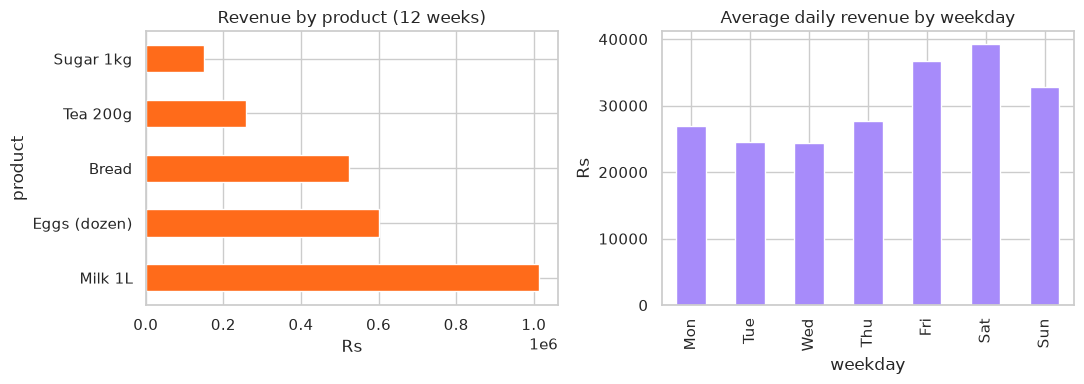

In [6]:
"""Real-life problem: clean a shop's sales log and turn it into a weekly stock plan."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
products = {"Milk 1L": 280, "Bread": 180, "Eggs (dozen)": 420, "Tea 200g": 450, "Sugar 1kg": 160}
base = {"Milk 1L": 40, "Bread": 30, "Eggs (dozen)": 15, "Tea 200g": 6, "Sugar 1kg": 10}
weekday_boost = np.array([1.0, 0.9, 0.9, 1.0, 1.3, 1.5, 1.2])        # Mon..Sun, weekends busier
rows = []
for day in pd.date_range("2026-07-06", periods=84):
    for p, mu in base.items():
        rows.append((day, p, rng.poisson(mu * weekday_boost[day.dayofweek])))
log = pd.DataFrame(rows, columns=["date", "product", "qty"])
# inject real-world dirt: duplicated rows and a typo quantity
log = pd.concat([log, log.sample(15, random_state=1)]).reset_index(drop=True)
log.loc[10, "qty"] = 999

# 1. Clean
before = len(log)
log = log.drop_duplicates()
log = log[log["qty"].between(0, 200)]
print(f"rows: {before} -> {len(log)} after removing duplicates and impossible quantities")

# 2. Revenue by product
log["revenue"] = log["qty"] * log["product"].map(products)
by_product = log.groupby("product")["revenue"].sum().sort_values(ascending=False)
print("\nRevenue over 12 weeks (Rs):\n", by_product.to_string())

# 3. Busiest weekdays
log["weekday"] = log["date"].dt.day_name().str[:3]
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = log.groupby("weekday")["revenue"].mean().reindex(order) * len(products)
print("\nAverage daily revenue by weekday (Rs):\n", by_day.round(0).to_string())

# 4. Weekly stock plan = mean + 1.65 * std of weekly units
weekly = log.groupby([pd.Grouper(key="date", freq="W-SUN"), "product"])["qty"].sum().unstack()
plan = pd.DataFrame({"avg_week": weekly.mean().round(0), "std": weekly.std().round(1)})
plan["stock_to_keep"] = np.ceil(plan["avg_week"] + 1.65 * plan["std"]).astype(int)
print("\nWeekly stock plan:\n", plan.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
by_product.plot.barh(ax=ax[0], color="#FF6B1A"); ax[0].set_title("Revenue by product (12 weeks)"); ax[0].set_xlabel("Rs")
by_day.plot.bar(ax=ax[1], color="#A78BFA"); ax[1].set_title("Average daily revenue by weekday"); ax[1].set_ylabel("Rs")
fig.tight_layout(); fig.savefig("session-01_shop_insights.png", dpi=110); plt.show()

### 🧩 Mini project: data science readiness report

Rows: 442  Columns: 11
          dtype  missing  unique
age     float64        0      58
sex     float64        0       2
bmi     float64        0     163
bp      float64        0     100
s1      float64        0     141
s2      float64        0     302
s3      float64        0      63
s4      float64        0      66
s5      float64        0     184
s6      float64        0      56
target  float64        0     214

Numeric summary:
            mean     std     min      max
age      -0.000   0.048  -0.107    0.111
sex       0.000   0.048  -0.045    0.051
bmi      -0.000   0.048  -0.090    0.171
bp       -0.000   0.048  -0.112    0.132
s1       -0.000   0.048  -0.127    0.154
s2        0.000   0.048  -0.116    0.199
s3       -0.000   0.048  -0.102    0.181
s4       -0.000   0.048  -0.076    0.185
s5        0.000   0.048  -0.126    0.134
s6        0.000   0.048  -0.138    0.136
target  152.133  77.093  25.000  346.000

Recommendation: target 'target' is numeric with many values -> regres

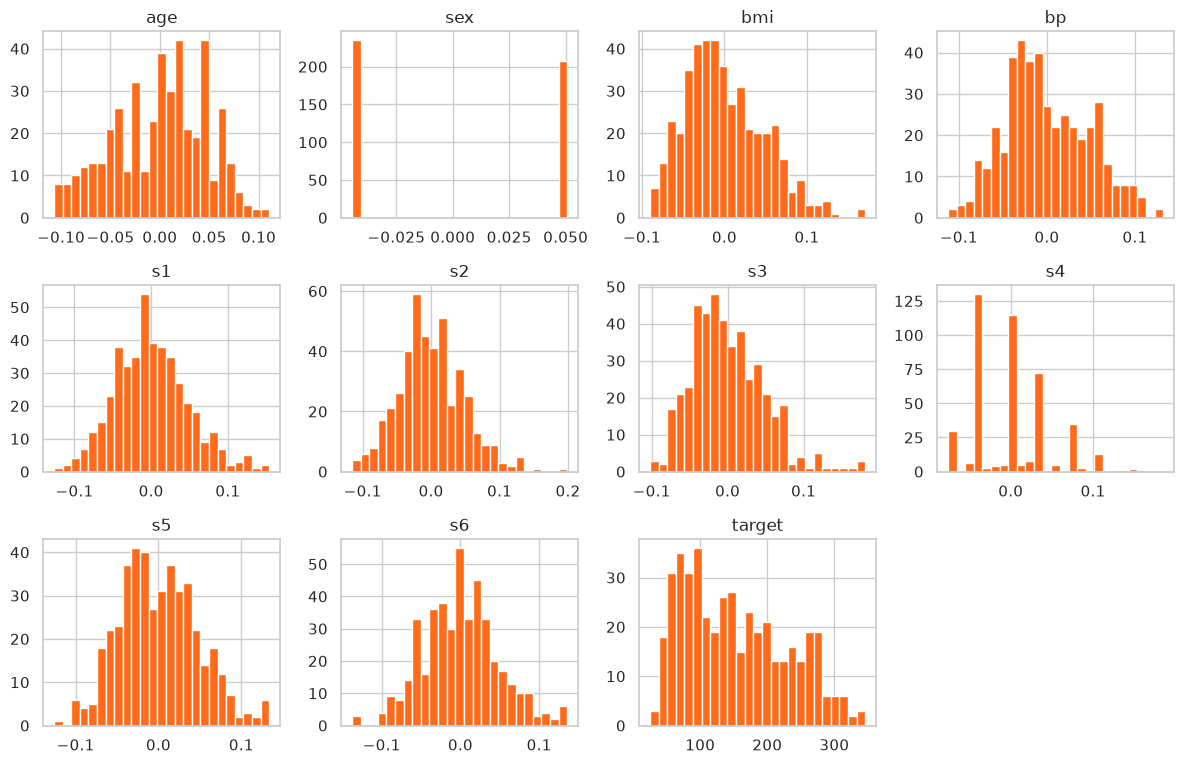

In [7]:
"""Mini project: automatic data profile and ML-type recommendation for any DataFrame."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

def profile(df: pd.DataFrame, target: str | None = None) -> None:
    print(f"Rows: {len(df)}  Columns: {df.shape[1]}")
    info = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                         "unique": df.nunique()})
    print(info.to_string())
    print("\nNumeric summary:\n", df.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
    if target is None:
        print("\nRecommendation: no target column -> unsupervised learning (clustering, PCA).")
    elif df[target].nunique() <= 10:
        print(f"\nRecommendation: target '{target}' has {df[target].nunique()} classes -> classification.")
    else:
        print(f"\nRecommendation: target '{target}' is numeric with many values -> regression.")

def histograms(df: pd.DataFrame, path: str) -> None:
    num = df.select_dtypes("number").columns
    cols = 4; rows = int(np.ceil(len(num) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 2.6 * rows))
    for ax, c in zip(axes.ravel(), num):
        ax.hist(df[c], bins=25, color="#FF6B1A", edgecolor="white"); ax.set_title(c)
    for ax in axes.ravel()[len(num):]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(path, dpi=100); plt.show()

data = load_diabetes(as_frame=True).frame        # 442 patients, 10 features, disease progression target
profile(data, target="target")
histograms(data, "session-01_mini_project_profile.png")